In [ ]:
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install astroquery
%pip install pytrends
%pip install astropy
%pip install requests
%pip install lxml

import sys
sys.path.insert(0, '..')
from popularity_queries import pytrends_query, wiki_pageviews

import astropy
import astroquery
import pytrends

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from astroquery.simbad import Simbad
from urllib.parse import quote

In [12]:
#reading asteroids file
file = pd.read_csv(r'C:\Users\mayad\OneDrive\Documents\GitHub\CelestialCelebs\sophia_research\asteroids.csv')
#file.head()

In [22]:
#getting rid of number in front of asteroid names
file["name_only"] = file["official_name"].str.split(" ", n=1).str[1]

#finding length of just the name
file["name_length"] = file["name_only"].str.len()

#switching to wikipedia title so that we can extract pageviews data
real = resolve_titles(file["official_name"].tolist())
file["wiki_title"] = file["official_name"].map(real).str.replace(" ", "_")

In [16]:
#ignore this for now b/c of change in wiki method

import requests

def resolve_titles(names):
    """Asks wikipedia where each title of a celestial body really directs to, returns resolved title as json"""
    header ={'User-Agent': 'WikiDataScraper/1.0 (https://github.com/etu8924/CelestialCelebs)'}
    final = {}

    for i in range(0, len(names), 50):
        batch = names[i:i+50]
        r = requests.get("https://en.wikipedia.org/w/api.php", params={"action": "query", "titles": "|".join(batch), "redirects": 1, "format": "json"}, headers=header,
        ).json()
        mapping = {}
        for item in r["query"].get("normalized", []):
            mapping[item["from"]] = item["to"]
        for item in r["query"].get("redirects", []):
            mapping[item["from"]] = item["to"]

        for name in batch:
            title = name
            while title in mapping:
                title = mapping[title]
            final[name] = title
    return final

In [25]:
#compiling viewage numbers


views = wiki_pageviews(file["wiki_title"].tolist(), start_date = "2025010100", end_date = "202609100")
file["total_views"] = file["wiki_title"].map(views.sum())
file[["official_name", "name_length", "total_views"]]

,official_name,name_length,total_views
0,1 Ceres,5,1253700
1,4 Vesta,5,405687
2,2 Pallas,6,188552
3,10 Hygiea,6,102582
4,704 Interamnia,10,29270
5,52 Europa,6,23511
6,511 Davida,6,19288
7,87 Sylvia,6,33723
8,15 Eunomia,7,31802
9,31 Euphrosyne,10,16277


In [ ]:
#debug check
#print(file.columns.tolist())

['official_name', 'name only', 'name length', 'wiki title']


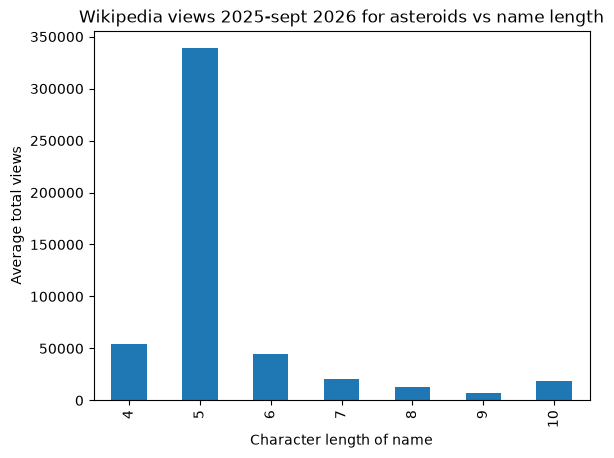

In [27]:
#graphing! just asteroids for rn :(

avg = file.groupby("name_length")["total_views"].mean()
avg.plot(kind="bar")
plt.xlabel("Character length of name")
plt.ylabel("Average total views")
plt.title("Wikipedia views 2025-sept 2026 for asteroids vs name length")
plt.show()

#pls note that all asteroids have names ranging from 4-10 characters

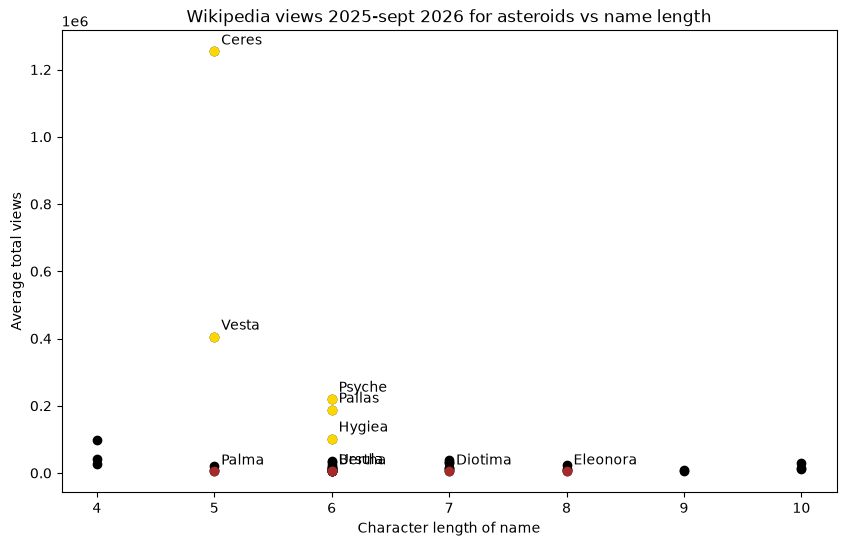

In [ ]:
#scatterplot for most and least viewed

top = file.nlargest(5,"total_views")
bottom = file.nsmallest(5, "total_views")
plt.figure(figsize=(10,6))

plt.scatter(file["name_length"], file["total_views"], color = "black", label = "middle asteroids")

plt.scatter(top["name_length"], top["total_views"], color="gold", label = "most viewed in 2025-2026 sept")
plt.scatter(bottom["name_length"], bottom["total_views"], color="brown", label="least viewed in 2025-2026 sept")

#writing name of asteroid for top/bottom asteroids

for _, row in pd.concat([top, bottom]).iterrows():
    plt.annotate(row["name_only"], (row["name_length"], row["total_views"]),
                textcoords="offset points", xytext=(5, 5))

plt.xlabel("Character length of name")
plt.ylabel("Average total views")
plt.title("Wikipedia views 2025-sept 2026 for asteroids vs name length")
plt.show()

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


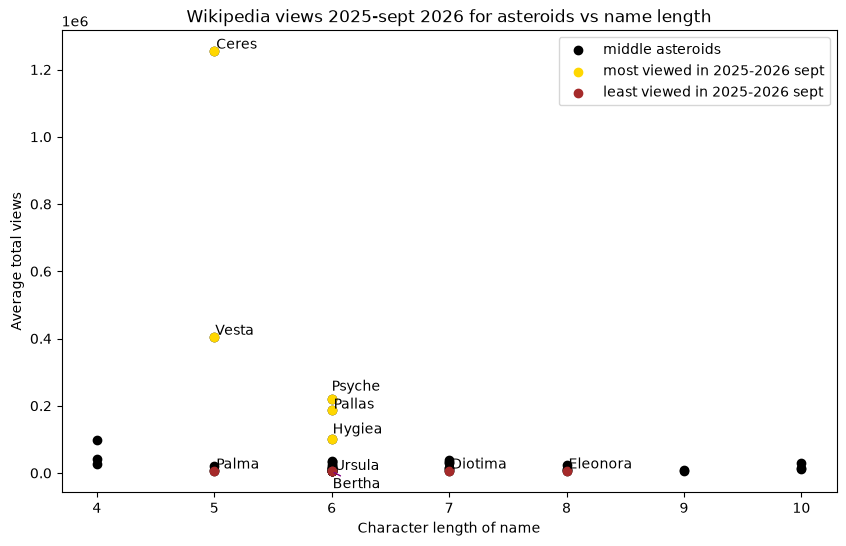

In [34]:
#lazy so i am importing package to clean graph for graphs that don't have names that overlap :( + adding legend

%pip install adjustText
from adjustText import adjust_text

top = file.nlargest(5,"total_views")
bottom = file.nsmallest(5, "total_views")
plt.figure(figsize=(10,6))

plt.scatter(file["name_length"], file["total_views"], color = "black", label = "middle asteroids")
plt.scatter(top["name_length"], top["total_views"], color="gold", label = "most viewed in 2025-2026 sept")
plt.scatter(bottom["name_length"], bottom["total_views"], color="brown", label="least viewed in 2025-2026 sept")

#writing name of asteroid for top/bottom asteroids
labels=[]
for _, row in pd.concat([top, bottom]).iterrows():
    labels.append(plt.text(row["name_length"], row["total_views"], row["name_only"]))
adjust_text(labels, arrowprops=dict(arrowstyle="-", color="purple"))

plt.xlabel("Character length of name")
plt.ylabel("Average total views")
plt.title("Wikipedia views 2025-sept 2026 for asteroids vs name length")
plt.legend()
plt.show()